#### ✅ Step 1: Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
import joblib


#### ✅ Step 2 : Load Data

In [2]:
# Update path to where your files are located

train = pd.read_csv("train.csv",sep=';', low_memory=True)
test = pd.read_csv("test.csv",sep=';')

print(train.shape, test.shape)
train.head()

(45211, 17) (4521, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


#### ✅Step 3: Exploratory Data Analysis

In [3]:
print(train.info())


<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB
None


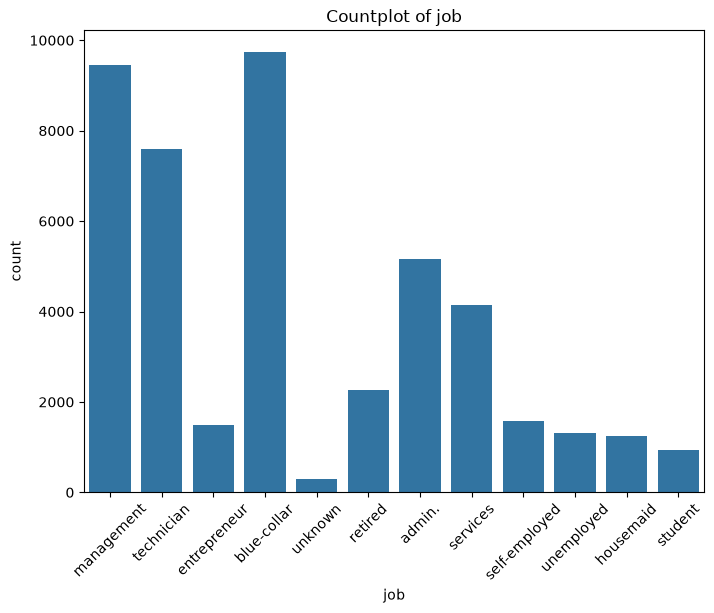

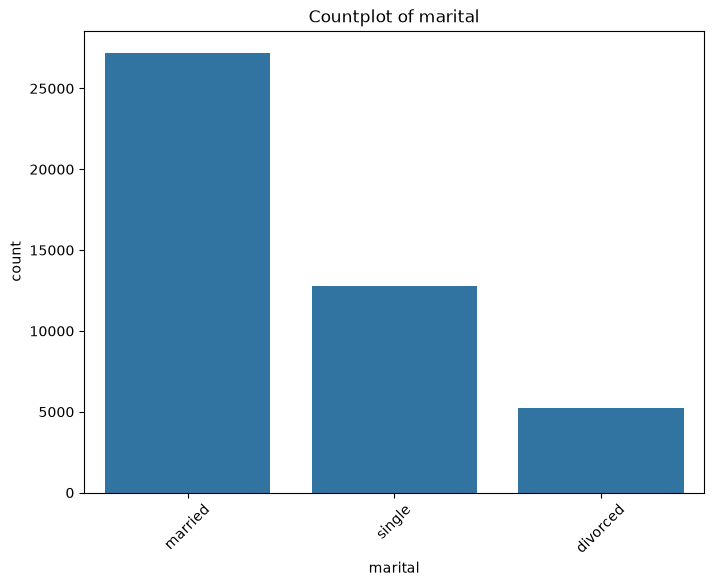

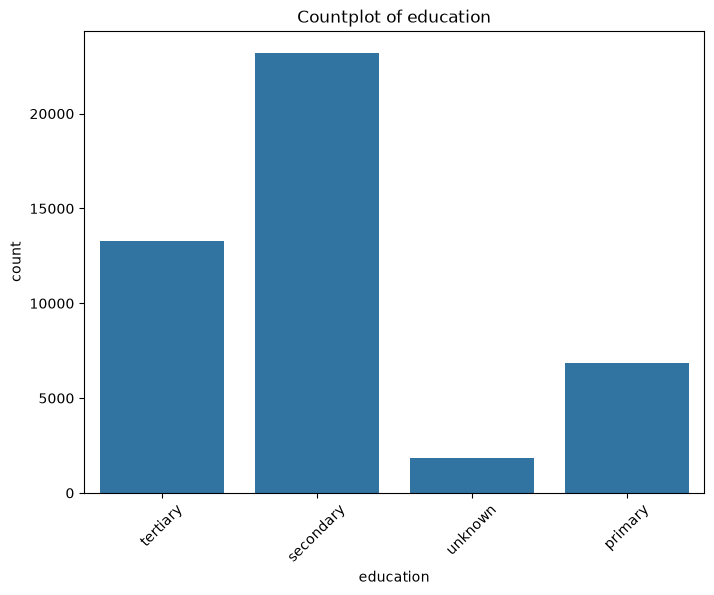

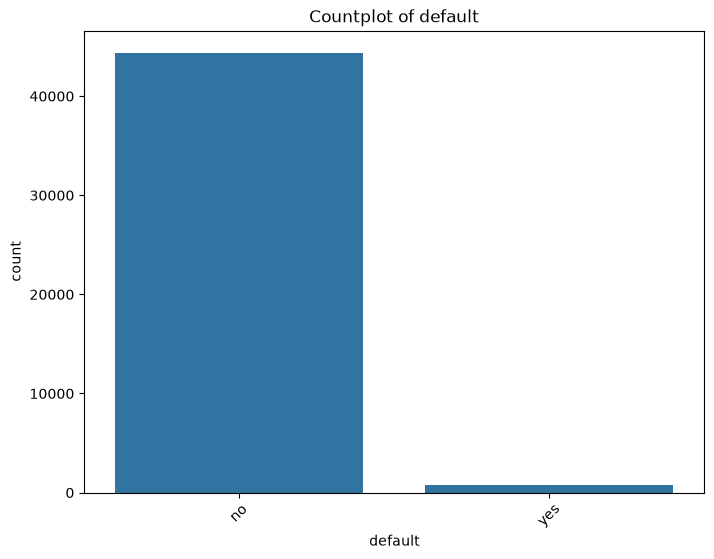

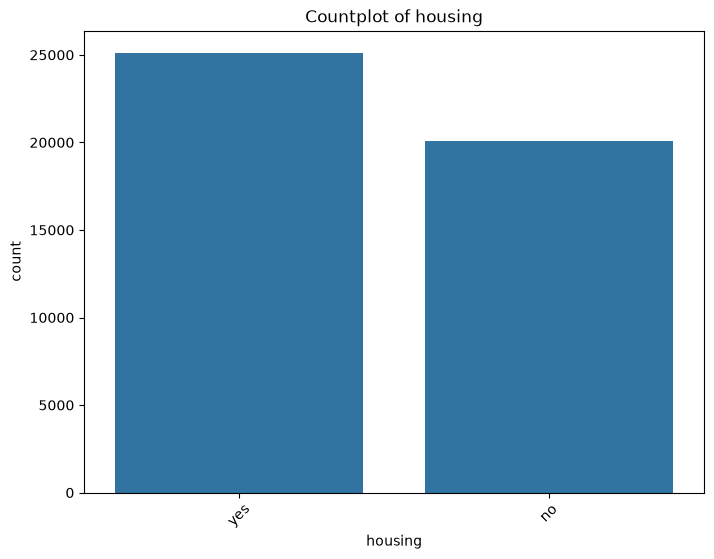

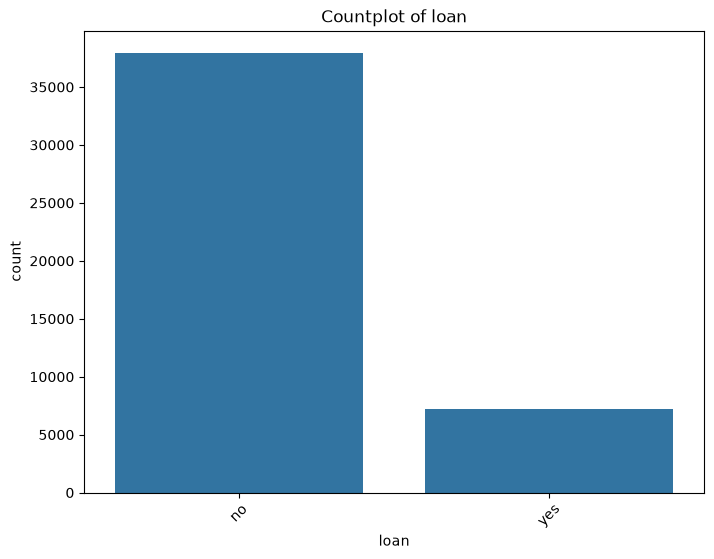

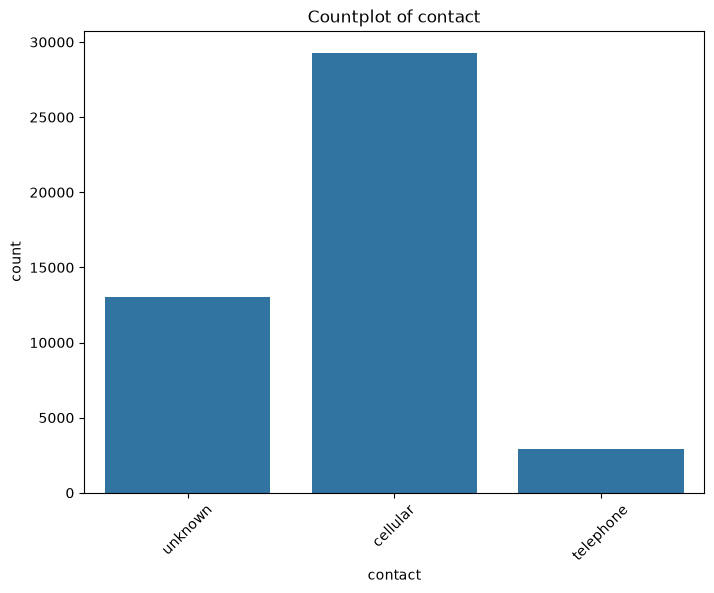

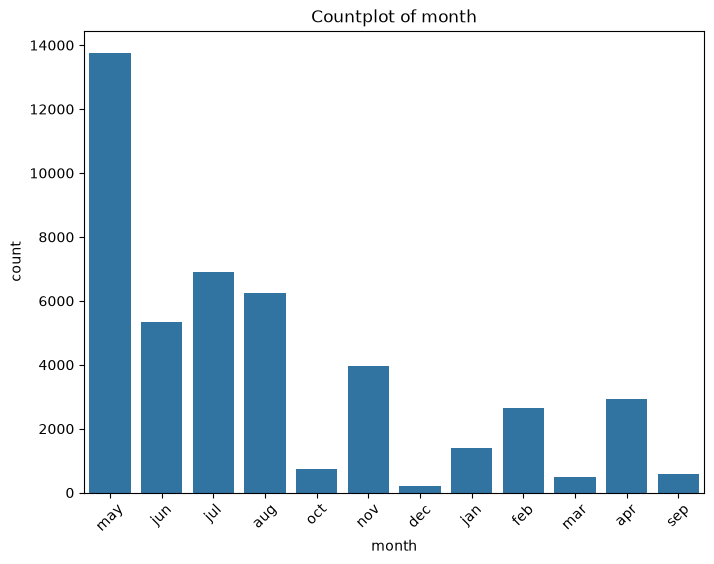

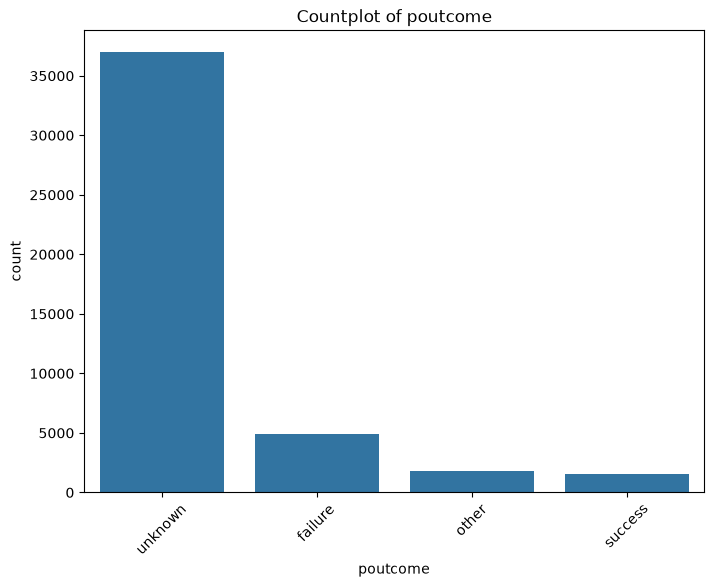

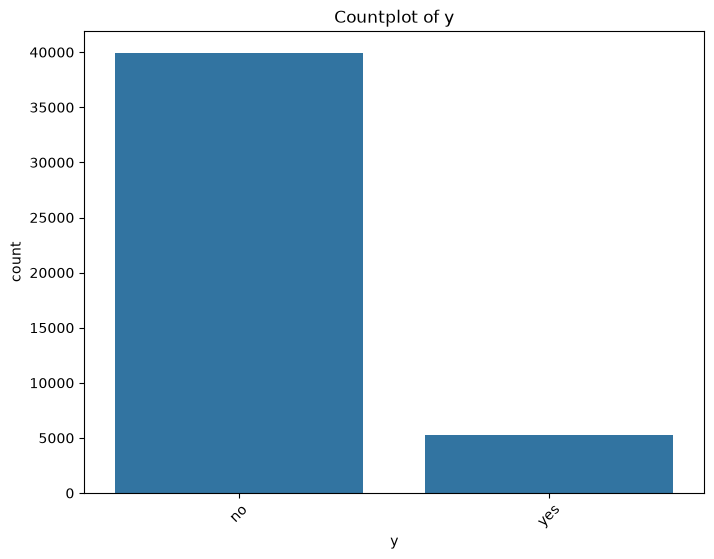

In [4]:
import seaborn as sns

# Define a list of categorical columns you want to plot
categorical_columns = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']

# Create subplots for each categorical column
for column in categorical_columns:
    plt.figure(figsize=(8, 6))  # Adjust figure size if needed
    sns.countplot(data=train, x=column)
    plt.title(f'Countplot of {column}')
    plt.xticks(rotation=45)  # Rotate x-axis labels for better readability (optional)
    plt.show()

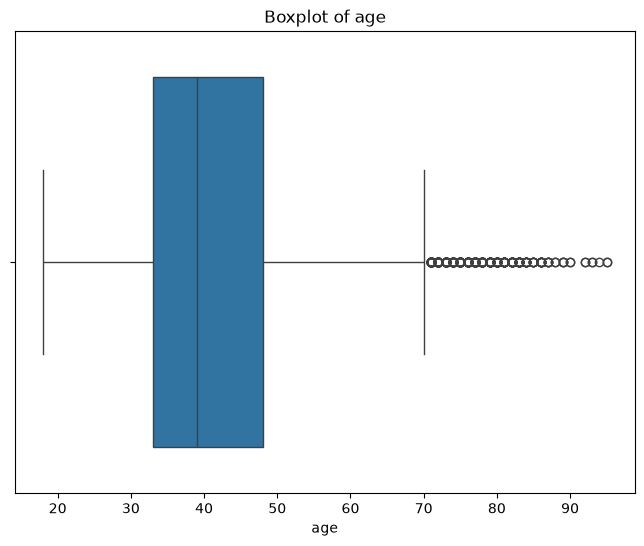

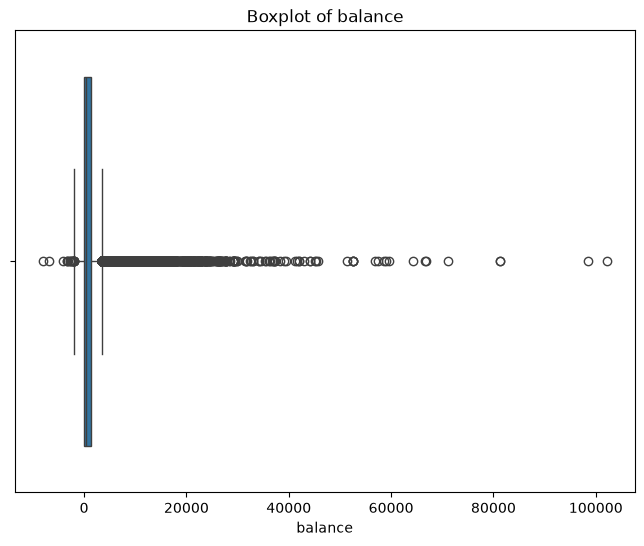

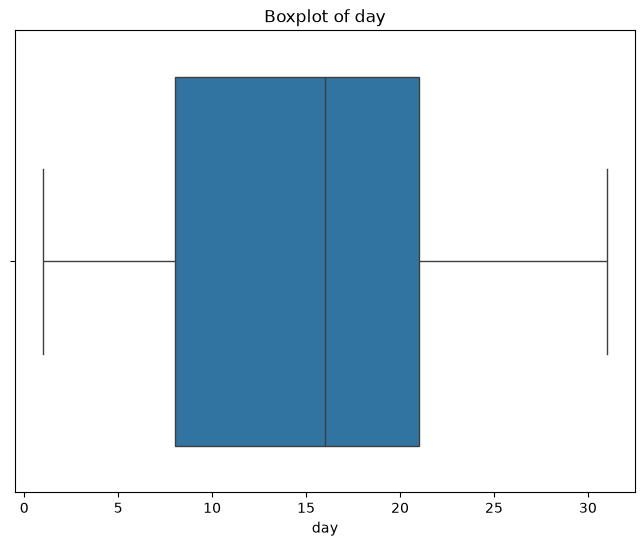

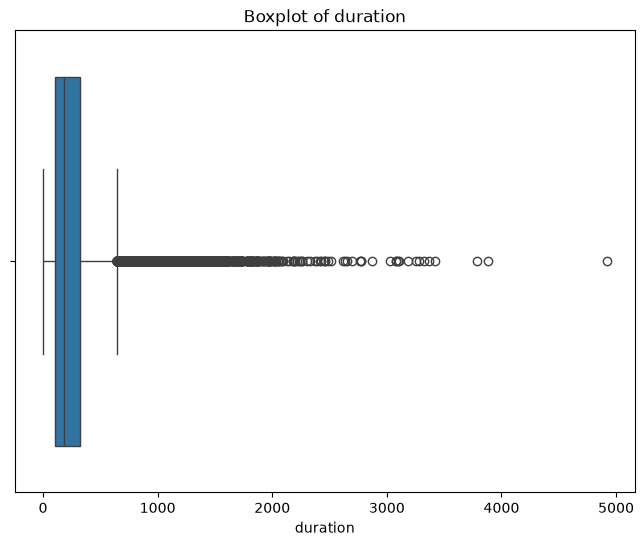

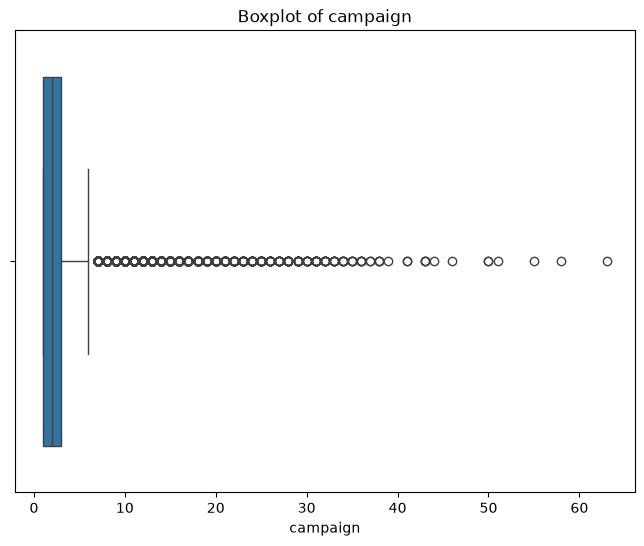

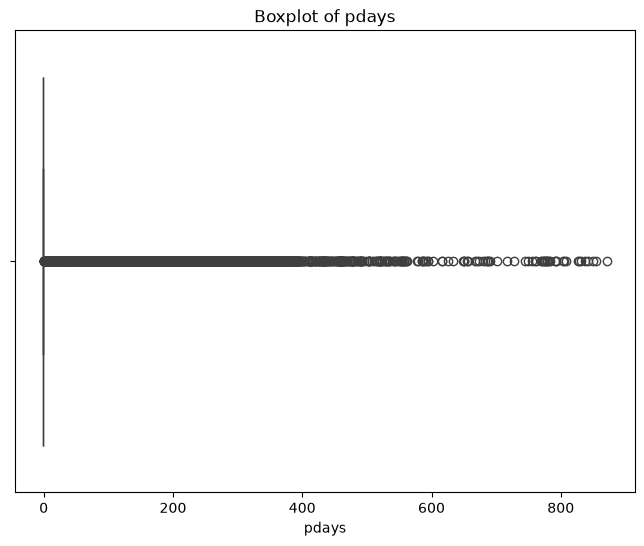

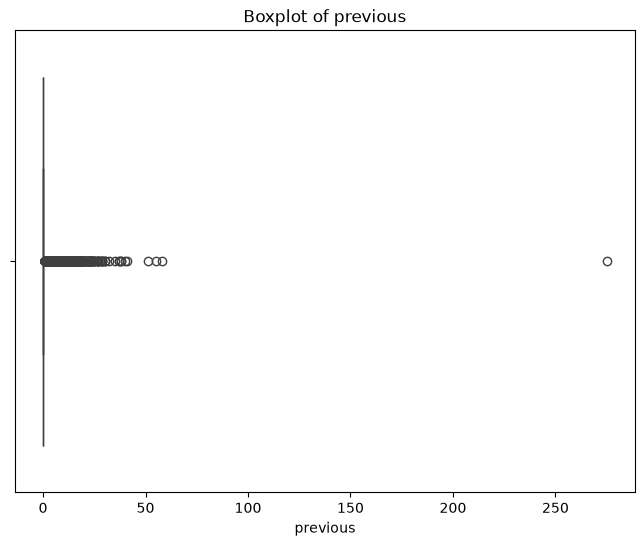

In [5]:
# Loop through numerical columns and create boxplots to identify outliers
for column in train.select_dtypes(include=['number']).columns:
  plt.figure(figsize=(8, 6))
  sns.boxplot(x=train[column])
  plt.title(f'Boxplot of {column}')
  plt.show()

#### ✅ Step 4: Encode Categorical Variables

In [6]:
categorical_cols = train.select_dtypes(include=['object']).columns.tolist()
categorical_cols.remove('y')  # We'll encode y separately

label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    train[col] = le.fit_transform(train[col])
    test[col] = le.transform(test[col])  # Ensure same encoding
    label_encoders[col] = le

# Encode target variable
le_y = LabelEncoder()
train['y'] = le_y.fit_transform(train['y'])
test['y'] = le_y.transform(test['y'])  # If 'y' is present in test set


C:\Users\User\AppData\Local\Temp\ipykernel_13168\198096655.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train.select_dtypes(include=['object']).columns.tolist()


##### Visualize class imbalance

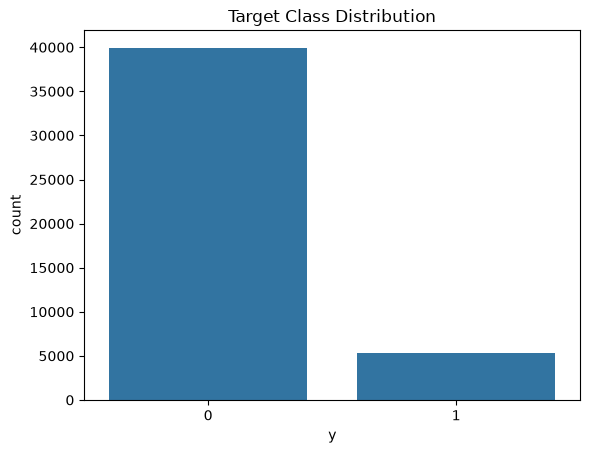

In [7]:
sns.countplot(x='y', data=train)
plt.title('Target Class Distribution')
plt.show()

In [8]:
from imblearn.over_sampling import SMOTE

# Separate features (X) and target (y)
X = train.drop('y', axis=1)
y = train['y']

# Apply SMOTE to balance the dataset
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Create a new balanced DataFrame
balanced_data = pd.concat([X_resampled, y_resampled], axis=1)

# Check the class distribution in the balanced dataset
print(balanced_data['y'].value_counts())

# Now you can use balanced_df for your model training

y
0    39922
1    39922
Name: count, dtype: int64


In [9]:
data = balanced_data.copy()
data.shape

(79844, 17)

#### ✅ Step 5: Feature Scaling

In [10]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_val, y_train, y_val = train_test_split(X_scaled, y, test_size=0.2, random_state=42)


#### ✅ Step 6: Model Training

In [12]:
pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 6.2 MB/s eta 0:00:08
   -- ------------------------------------- 3.7/48.9 MB 12.7 MB/s eta 0:00:04
   ----- ---------------------------------- 7.1/48.9 MB 14.2 MB/s eta 0:00:03
   -------- ------------------------------- 10.2/48.9 MB 14.4 MB/s eta 0:00:03
   ---------- ----------------------------- 12.8/48.9 MB 14.7 MB/s eta 0:00:03
   ------------- -------------------------- 16.0/48.9 MB 14.4 MB/s eta 0:00:03
   -------------- ------------------------- 18.4/48.9 MB 13.7 MB/s eta 0:00:03
   ----------------- ---------------------- 21.2/48.9 MB 13.6 MB/s eta 0:00:03
   ------------------- -------------------- 23.9/48.9 MB 13.4 MB/s eta 0:00:02
   --------------------- ------------------ 26.7/48.9 MB 13.4 MB/s eta 0:00:02
   ----------------------- ---------------- 29.4/48.9 MB 13.4 MB/s eta 0:00:02
   -------------------------- ------------- 32.2/48.9 MB 13.4 MB/

In [13]:
from sklearn.feature_selection import RFE
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

# Assuming X and y are your features and target variable
X = data.drop('y', axis=1)
y = data['y']
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Define the estimators
estimators = [
    DecisionTreeClassifier(),
    RandomForestClassifier(),
    GradientBoostingClassifier(),
    XGBClassifier()
]

# Loop through the estimators and perform feature selection
for estimator in estimators:
  print(f"Performing feature selection with {type(estimator).__name__}")

  # Create RFE object with the estimator and desired number of features to select
  rfe = RFE(estimator=estimator, n_features_to_select=8)  # You can adjust the number of features

  # Fit RFE to the training data
  rfe.fit(X_train, y_train)

  # Get the selected features
  selected_features = X_train.columns[rfe.support_]

  # Print the selected features
  print("Selected Features:", selected_features)
  print("-" * 100)

Performing feature selection with DecisionTreeClassifier
Selected Features: Index(['age', 'balance', 'housing', 'contact', 'day', 'month', 'duration',
       'poutcome'],
      dtype='str')
----------------------------------------------------------------------------------------------------
Performing feature selection with RandomForestClassifier
Selected Features: Index(['age', 'balance', 'housing', 'contact', 'day', 'month', 'duration',
       'pdays'],
      dtype='str')
----------------------------------------------------------------------------------------------------
Performing feature selection with GradientBoostingClassifier
Selected Features: Index(['job', 'housing', 'loan', 'contact', 'month', 'duration', 'campaign',
       'poutcome'],
      dtype='str')
----------------------------------------------------------------------------------------------------
Performing feature selection with XGBClassifier
Selected Features: Index(['education', 'housing', 'loan', 'contact', 'month'

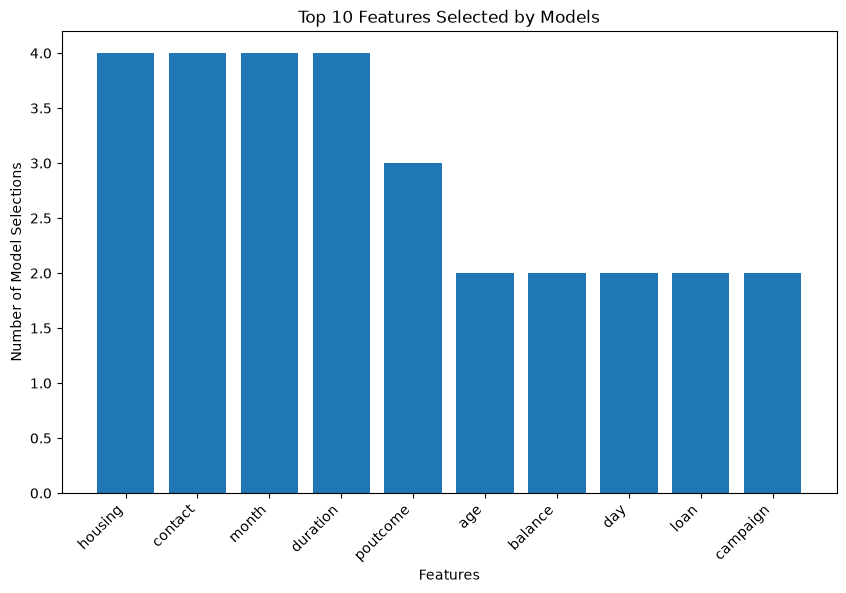

Overall Top 8 Features: ['housing', 'contact', 'month', 'duration', 'poutcome', 'age', 'balance', 'day', 'loan', 'campaign']


In [14]:
# Assuming you have a list of selected features for each model
# Create a dictionary to store the feature counts
feature_counts = {}
for estimator in estimators:
  rfe = RFE(estimator=estimator, n_features_to_select=8)
  rfe.fit(X_train, y_train)
  selected_features = X_train.columns[rfe.support_]
  for feature in selected_features:
    if feature in feature_counts:
      feature_counts[feature] += 1
    else:
      feature_counts[feature] = 1
# Sort features by count in descending order
sorted_features = sorted(feature_counts.items(), key=lambda item: item[1], reverse=True)

# Get the top 10 features
top_8_features = [feature for feature, count in sorted_features[:10]]

# Create a bar chart
plt.figure(figsize=(10, 6))
plt.bar(range(len(top_8_features)), [count for feature, count in sorted_features[:10]])
plt.xticks(range(len(top_8_features)), top_8_features, rotation=45, ha='right')
plt.xlabel('Features')
plt.ylabel('Number of Model Selections')
plt.title('Top 10 Features Selected by Models')
plt.show()

# Print the overall top 8 features
print("Overall Top 8 Features:", top_8_features)

In [15]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
# train models

for estimator in estimators:
  estimator.fit(X_train, y_train)
  y_pred = estimator.predict(X_test)
  print(f"Model: {type(estimator).__name__}")
  print(f'Accuracy Score : {accuracy_score(y_test,y_pred):.2f}')
  print(f'Precision Score : {precision_score(y_test,y_pred):.2f}')
  print(f'Recall Score : {recall_score(y_test,y_pred):.2f}')
  print(f'F1_Score : {f1_score(y_test,y_pred):.2f}')
  print("-" * 50)
  print(classification_report(y_test, y_pred))
  print("-" * 50)
  print(f'This model : {type(estimator).__name__} done train!')

Model: DecisionTreeClassifier
Accuracy Score : 0.90
Precision Score : 0.89
Recall Score : 0.91
F1_Score : 0.90
--------------------------------------------------
              precision    recall  f1-score   support

           0       0.90      0.88      0.89      7908
           1       0.89      0.91      0.90      8061

    accuracy                           0.90     15969
   macro avg       0.90      0.90      0.90     15969
weighted avg       0.90      0.90      0.90     15969

--------------------------------------------------
This model : DecisionTreeClassifier done train!
Model: RandomForestClassifier
Accuracy Score : 0.93
Precision Score : 0.91
Recall Score : 0.95
F1_Score : 0.93
--------------------------------------------------
              precision    recall  f1-score   support

           0       0.95      0.91      0.93      7908
           1       0.91      0.95      0.93      8061

    accuracy                           0.93     15969
   macro avg       0.93      0.9

In [16]:
import warnings
warnings.filterwarnings("ignore")

In [17]:
# prompt: how about using randomizedsearchcv for searching best parameters on my models

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

# Define parameter distributions for each model
param_distributions = {
    'DecisionTreeClassifier': {
        'criterion': ['gini', 'entropy'],
        'max_depth': randint(2, 10),
        'min_samples_split': randint(2, 20),
        'min_samples_leaf': randint(1, 10)
    },
    'RandomForestClassifier': {
        'n_estimators': randint(50, 200),
        'max_depth': randint(2, 10),
        'min_samples_split': randint(2, 20),
        'min_samples_leaf': randint(1, 10),
        'bootstrap': [True, False]
    }, 'GradientBoostingClassifier': {
        'n_estimators': randint(50, 200),
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': randint(2, 10),
        'min_samples_split': randint(2, 20),
        'min_samples_leaf': randint(1, 10)
    },
    'XGBClassifier': {
        'n_estimators': randint(50, 200),
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': randint(2, 10),
        'min_child_weight': randint(1, 10),
        'gamma': [0, 0.1, 0.2]
    }
}
# Perform RandomizedSearchCV for each model
for estimator in estimators:
  model_name = type(estimator).__name__
  print(f"Performing RandomizedSearchCV for {model_name}")

  # Create RandomizedSearchCV object
  random_search = RandomizedSearchCV(
      estimator=estimator,
      param_distributions=param_distributions.get(model_name, {}),
      n_iter=20,  # Number of parameter settings that are sampled
      cv=5,
      scoring='accuracy',  # You can choose other scoring metrics
      random_state=42,
      n_jobs=-1  # Use all available CPU cores
  )

  # Fit RandomizedSearchCV to the training data
  random_search.fit(X_train, y_train) # Print the best parameters and score
  print("Best Parameters:", random_search.best_params_)
  print("Best Score:", random_search.best_score_)
  print("-" * 50)


  # Train the model with the best parameters
  best_estimator = random_search.best_estimator_
  best_estimator.fit(X_train, y_train)

  # Make predictions on the test set
  y_pred = best_estimator.predict(X_test)  # Evaluate the model
  print(f"Model: {model_name} with best parameters")
  print(f'Accuracy Score : {accuracy_score(y_test,y_pred):.2f}')
  print(f'Precision Score : {precision_score(y_test,y_pred):.2f}')
  print(f'Recall Score : {recall_score(y_test,y_pred):.2f}')
  print(f'F1_Score : {f1_score(y_test,y_pred):.2f}')
  print("-" * 50)
  print(classification_report(y_test, y_pred))
  print("-" * 50)
  print(f'This model : {model_name} with best parameters done train!')

Performing RandomizedSearchCV for DecisionTreeClassifier
Best Parameters: {'criterion': 'entropy', 'max_depth': 9, 'min_samples_leaf': 3, 'min_samples_split': 3}
Best Score: 0.8757416829745598
--------------------------------------------------
Model: DecisionTreeClassifier with best parameters
Accuracy Score : 0.88
Precision Score : 0.86
Recall Score : 0.90
F1_Score : 0.88
--------------------------------------------------
              precision    recall  f1-score   support

           0       0.89      0.85      0.87      7908
           1       0.86      0.90      0.88      8061

    accuracy                           0.88     15969
   macro avg       0.88      0.88      0.88     15969
weighted avg       0.88      0.88      0.88     15969

--------------------------------------------------
This model : DecisionTreeClassifier with best parameters done train!
Performing RandomizedSearchCV for RandomForestClassifier
Best Parameters: {'bootstrap': True, 'max_depth': 9, 'min_samples_lea

In [18]:
model = GradientBoostingClassifier(learning_rate=0.2,max_depth=8,n_estimators=153,min_samples_leaf=8,min_samples_split=5)
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_val)

# Evaluation
print("Accuracy:", accuracy_score(y_val, y_pred))
print(classification_report(y_val, y_pred))

Accuracy: 0.8793541966161672
              precision    recall  f1-score   support

           0       0.88      1.00      0.94      7952
           1       0.00      0.00      0.00      1091

    accuracy                           0.88      9043
   macro avg       0.44      0.50      0.47      9043
weighted avg       0.77      0.88      0.82      9043



#### ✅ Step 7: Save Model and Scaler

In [19]:
# import pickle

# # Save model
# with open('bank_model.pkl', 'wb') as f:
#     pickle.dump(model, f)

# # Save scaler
# with open('scaler.pkl', 'wb') as f:
#     pickle.dump(scaler, f)

# # Save encoders
# with open('encoders.pkl', 'wb') as f:
#     pickle.dump(label_encoders, f)

# # Save target encoder (optional if using in frontend)
# with open('label_encoder_y.pkl', 'wb') as f:
#     pickle.dump(le_y, f)

import pickle

# Let's say X is your feature DataFrame
feature_columns = X.columns.tolist()

# Save model, scaler, and columns
with open("banking_model.pkl", "wb") as f:
    pickle.dump(model, f)

with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

# Save all label encoders (features + target) in one dictionary
label_encoders['target_y'] = le_y

# Save to a file
with open('label_encoders.pkl', 'wb') as f:
    pickle.dump(label_encoders, f)

with open("feature_columns.pkl", "wb") as f:
    pickle.dump(feature_columns, f)



In [ ]:
# !streamlit run app.py
